# Causal features, forecast fitting and calibration

Executed research analysis on real local inputs or committed aggregate reports. Historical/validation scope is labeled explicitly. No test rescoring occurs. Use the isolated repository environment plus Jupyter, pandas and matplotlib.

In [1]:
from pathlib import Path
import os, json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists()
os.chdir(ROOT)
for path in [ROOT, ROOT / 'src']:
    if str(path) not in sys.path: sys.path.insert(0, str(path))
FIGURES = ROOT / 'docs' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))
def show_figure(fig, name):
    path = FIGURES / (name + '.png')
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(path)))
print('Executed analysis; Python', sys.version.split()[0])
print('Only aggregate outputs and figures are retained; raw rows/weights remain ignored.')


Executed analysis; Python 3.14.2
Only aggregate outputs and figures are retained; raw rows/weights remain ignored.


## Visible causal feature and forecasting algorithms
The code below is the production causal feature builder, train-only scaling/ridge fit, finite-sample quantile and chronological selection logic. Defining code does not train on calibration/test data. Labels are intentionally future-shifted only as targets; they are excluded from FEATURES.

### Visible production core: `src/features/multi_asset.py`

These readable definitions are copied from the executed production module (SHA256 `4977ec627b92bf499a4021ecadd79db7b34fe6739cc0f07acc7e3e111202467f`). They expose the algorithm directly; optional full studies still use production entrypoints and fresh outputs. No hidden source execution or encoded bootstrap is used.

In [2]:
"""Causal features; delayed label t+1 -> t+2; peer features lag one observation."""
import numpy as np
import pandas as pd
from src.data.multi_asset import ASSETS, validate_panel

OWN_FEATURES = ["return_1", "momentum_3", "momentum_5", "momentum_10", "momentum_20", "momentum_60",
                "volatility_5", "volatility_20", "volatility_60", "ewma_volatility", "volatility_ratio",
                "downside_20", "drawdown_60", "zscore_20", "rsi_14", "autocorrelation_20", "skew_20", "gap_days"]
PEER_FEATURES = ["peer_return_lag1", "peer_momentum_lag1", "peer_volatility_lag1", "relative_momentum"]
FEATURES = OWN_FEATURES + PEER_FEATURES


def build_panel_features(panel, assets=ASSETS):
    panel = validate_panel(panel, assets)
    log = np.log(panel[list(assets)])
    returns = log.diff()
    result = {}
    for asset in assets:
        r, close = returns[asset], panel[asset]
        frame = pd.DataFrame({"date": panel.date, "close": close, "return_1": r})
        for period in [3, 5, 10, 20, 60]:
            frame[f"momentum_{period}"] = log[asset].diff(period)
        for period in [5, 20, 60]:
            frame[f"volatility_{period}"] = r.rolling(period).std()
        frame["ewma_volatility"] = r.ewm(span=20, adjust=False, min_periods=20).std()
        frame["volatility_ratio"] = frame.volatility_5 / frame.volatility_20.clip(lower=1e-8)
        frame["downside_20"] = np.sqrt(r.clip(upper=0).pow(2).rolling(20).mean())
        frame["drawdown_60"] = close / close.rolling(60).max() - 1
        frame["zscore_20"] = (log[asset] - log[asset].rolling(20).mean()) / log[asset].rolling(20).std().clip(lower=1e-8)
        up, down = r.clip(lower=0).rolling(14).mean(), -r.clip(upper=0).rolling(14).mean()
        frame["rsi_14"] = up / (up + down).clip(lower=1e-8)
        frame["autocorrelation_20"] = r.rolling(20).corr(r.shift(1)).fillna(0)
        frame["skew_20"] = r.rolling(20).skew().fillna(0)
        frame["gap_days"] = panel.date.diff().dt.total_seconds() / 86400
        peers = [other for other in assets if other != asset]
        frame["peer_return_lag1"] = returns[peers].mean(axis=1).shift(1)
        frame["peer_momentum_lag1"] = log[peers].diff(5).mean(axis=1).shift(1)
        frame["peer_volatility_lag1"] = returns[peers].rolling(20).std().mean(axis=1).shift(1)
        frame["relative_momentum"] = frame.momentum_20 - log[peers].diff(20).mean(axis=1).shift(1)
        frame["execution_date"] = panel.date.shift(-1)
        frame["target_date"] = panel.date.shift(-2)
        frame["target"] = r.shift(-2)
        result[asset] = frame.dropna(subset=FEATURES).reset_index(drop=True)
    return result


In [3]:
import math
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from src.models.advanced import feature_split
from src.data.multi_asset import ASSETS,validate_panel

### Visible production core: `src/models/uncertainty.py`

These readable definitions are copied from the executed production module (SHA256 `c2017dc29d94810704169e60cae9c8b477b9183b07a58233bda274c3ac048fc7`). They expose the algorithm directly; optional full studies still use production entrypoints and fresh outputs. No hidden source execution or encoded bootstrap is used.

In [4]:
def finite_quantile(values, alpha=.1):
    """Finite-sample order statistic; no interpolation or heldout residual fitting."""
    values = np.asarray(values, float)
    if values.ndim != 1 or not len(values) or not np.isfinite(values).all() or (values < 0).any() or not 0 < alpha < 1:
        raise ValueError("Finite nonnegative calibration residuals and alpha in (0,1) required")
    rank = math.ceil((len(values) + 1) * (1 - alpha))
    if rank > len(values):
        raise ValueError("Insufficient calibration support for requested coverage")
    return float(np.sort(values)[rank - 1])


def fit(frame, spec):
    if frame.empty or not np.isfinite(frame[FEATURES + ['target']].to_numpy(float)).all():
        raise ValueError("Finite training features and matured targets required")
    if spec['kind'] == 'zero':
        return None
    if spec['kind'] != 'ridge' or not math.isfinite(spec['alpha']) or spec['alpha'] <= 0:
        raise ValueError("Unsupported regularized candidate")
    # No fitted intercept: centered features avoid learning an unstable unconditional drift.
    return make_pipeline(StandardScaler(), Ridge(alpha=spec['alpha'], fit_intercept=False)).fit(frame[FEATURES], frame.target)


def point(model, frame):
    if not np.isfinite(frame[FEATURES].to_numpy(float)).all():
        raise ValueError("Forecast features must be finite")
    return np.zeros(len(frame)) if model is None else model.predict(frame[FEATURES])


def interval_metrics(actual, prediction, width, alpha=.1):
    actual, prediction, width = [np.asarray(x, float) for x in (actual, prediction, width)]
    if actual.ndim != 1 or not len(actual) or actual.shape != prediction.shape or width.shape != actual.shape or not all(np.isfinite(x).all() for x in [actual, prediction, width]) or (width < 0).any() or not 0 < alpha < 1:
        raise ValueError("Aligned finite observations, forecasts and nonnegative half-widths required")
    low, high = prediction - width, prediction + width
    score = 2 * width + (2 / alpha) * (np.maximum(low - actual, 0) + np.maximum(actual - high, 0))
    return {'rows': len(actual), 'rmse': float(np.sqrt(np.mean((actual - prediction) ** 2))),
            'coverage': float(np.mean((actual >= low) & (actual <= high))),
            'mean_width': float(np.mean(2 * width)), 'mean_interval_score': float(score.mean())}


def forecast(checkpoint, supplied):
    if checkpoint.get('version') != 'uncertainty_v2' or checkpoint['assets'] != ASSETS:
        raise ValueError("Unsupported uncertainty checkpoint")
    supplied = validate_panel(supplied)
    context = validate_panel(checkpoint['context'])
    overlap = supplied.merge(context, on='date', suffixes=('_new', '_old'))
    if any(not np.allclose(overlap[a + '_new'], overlap[a + '_old'], atol=1e-12, rtol=0) for a in ASSETS):
        raise ValueError("Input revises saved source context")
    panel = validate_panel(pd.concat([context, supplied]).drop_duplicates('date').sort_values('date').reset_index(drop=True))
    frames, parts = build_panel_features(panel), []
    for asset in ASSETS:
        rows = frames[asset].loc[frames[asset].date.isin(supplied.date) & (frames[asset].date > context.date.max())].copy()
        if rows.empty:
            continue
        bundle = checkpoint['bundles'][asset]
        if not all(math.isfinite(bundle[key]) and bundle[key] >= 0 for key in ['absolute_quantile', 'normalized_quantile']):
            raise ValueError('Checkpoint interval calibration must be finite and nonnegative')
        values = point(bundle['model'], rows)
        dynamic = np.maximum(rows.ewma_volatility.to_numpy(), 1e-5) * bundle['normalized_quantile']
        parts.append(pd.DataFrame({'date': rows.date, 'asset': asset, 'prediction': values,
                                 'lower': values - dynamic, 'upper': values + dynamic,
                                 'constant_lower': values - bundle['absolute_quantile'],
                                 'constant_upper': values + bundle['absolute_quantile']}))
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()


def search_candidates(development, plan):
    """Chronological model search without accessing calibration or test rows."""
    candidates = []
    for spec in plan['candidates']:
        squared, count = 0., 0
        folds = []
        for year in plan['validation_years']:
            fold_squared, fold_count = 0., 0
            for asset in ASSETS:
                training, validation, _ = feature_split(development[asset], f'{year}-01-01', f'{year}-12-31')
                residual = validation.target.to_numpy() - point(fit(training, spec), validation)
                fold_squared += float(residual @ residual)
                fold_count += len(residual)
            folds.append({'year': year, 'rows': fold_count, 'rmse': math.sqrt(fold_squared / fold_count)})
            squared += fold_squared
            count += fold_count
        candidates.append({'spec': spec, 'pooled_validation_rmse': math.sqrt(squared / count), 'folds': folds})
    return candidates, min(candidates, key=lambda x: x['pooled_validation_rmse'])['spec']


## Recorded chronological validation table
Selection used 2021–24 folds only. Zero is an eligible model. Wider-alpha followups and shared/recency proposals did not satisfy the adoption gate; no candidate is selected using the chart below.

year,2021,2022,2023,2024
candidate,,,,
"{""alpha"": 100, ""kind"": ""ridge""}",0.003508,0.004910,0.004030,0.003104
"{""alpha"": 1000, ""kind"": ""ridge""}",0.003500,0.004877,0.004016,0.003076
"{""alpha"": 10000, ""kind"": ""ridge""}",0.003503,0.004867,0.004001,0.003047
"{""kind"": ""zero""}",0.003510,0.004874,0.004001,0.003042


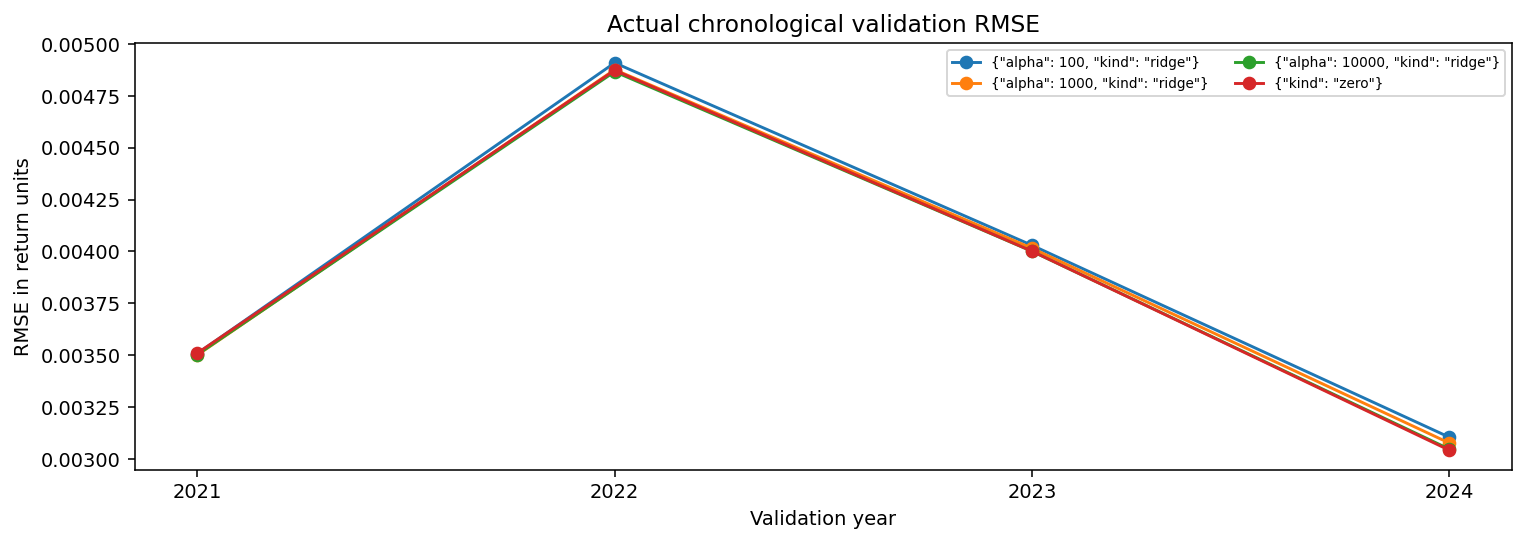

Selected on development: {'kind': 'ridge', 'alpha': 10000}


In [5]:
selection=read_json('models/uncertainty-v2/selection.json')
rows=[]
for candidate in selection['candidates']:
    label=json.dumps(candidate['spec'],sort_keys=True)
    for fold in candidate['folds']:rows.append({'candidate':label,**fold})
folds=pd.DataFrame(rows)
display(folds.pivot(index='candidate',columns='year',values='rmse'))
fig,ax=plt.subplots(figsize=(11,4))
for label,values in folds.groupby('candidate'):
    ax.plot(values.year,values.rmse,marker='o',label=label)
ax.set(title='Actual chronological validation RMSE',xlabel='Validation year',ylabel='RMSE in return units')
ax.legend(fontsize=7,ncol=2)
ax.set_xticks(sorted(folds.year.unique()))
show_figure(fig,'quant_chronological_validation')
print('Selected on development:',selection['selected'])

## Optional validation-only reproduction
Full search is explicitly disabled here. The root runner uses the frozen cached historical paths and refuses to overwrite output. No observed-test release occurs.

In [6]:
RUN_TRAIN=False
if RUN_TRAIN:
    import subprocess
    from datetime import datetime,timezone
    output='models/notebook-shared-'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    subprocess.run([sys.executable,'train.py','shared','--output',output],check=True)
print('No training/test scoring executed:',not RUN_TRAIN)

No training/test scoring executed: True


## Causal saved inference checks
Only counts and mechanics are shown; no per-observation source/prediction tables are committed. An ignored checkpoint is required.

In [7]:
import joblib
checkpoint_path=Path('models/uncertainty-v2/bundle.joblib')
if checkpoint_path.exists():
    checkpoint=joblib.load(checkpoint_path)
    print('Saved version:',checkpoint['version'],'assets:',checkpoint['assets'])
    print('Full prefix context rows:',len(checkpoint['context']))
    print('Mean-model types:',[type(checkpoint['bundles'][asset]['model']).__name__ for asset in ASSETS])
    print('Quantiles finite/nonnegative:',all(np.isfinite(checkpoint['bundles'][a]['normalized_quantile']) and checkpoint['bundles'][a]['normalized_quantile']>=0 for a in ASSETS))
else: print('Train or provide ignored checkpoint first.')

Saved version: uncertainty_v2 assets: ['FXEURCAD', 'FXGBPCAD', 'FXAUDCAD']
Full prefix context rows: 2244
Mean-model types: ['Pipeline', 'Pipeline', 'Pipeline']
Quantiles finite/nonnegative: True


## Actual saved-checkpoint replay
This reruns inference mechanics on the existing complete observed panel, without labels, scoring, model fitting or calibration. Only verification counts are committed; per-observation forecasts remain private. It does not provide new independent accuracy evidence.

In [8]:
if checkpoint_path.exists():
    supplied=pd.read_csv('data/external/multi-asset-v1/holdout/panel.csv')
    replay=forecast(checkpoint,supplied)
    numeric=['prediction','lower','upper','constant_lower','constant_upper']
    assert len(replay)>0 and np.isfinite(replay[numeric].to_numpy()).all()
    assert (replay.lower<=replay.prediction).all() and (replay.prediction<=replay.upper).all()
    print('Saved checkpoint replay rows:',len(replay),'assets:',replay.asset.nunique())
    print('Finite scalar forecasts/bounds:',replay[numeric].size)
    print('Ordered valid intervals:',bool((replay.lower<=replay.upper).all()))

Saved checkpoint replay rows: 588 assets: 3
Finite scalar forecasts/bounds: 2940
Ordered valid intervals: True
